# ROI_processing

In [1]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData

import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys
import seaborn as sns

import hotspot

/home/sergio/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/sergio/.local/lib/python3.10/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [2]:
# Technology 1: Xenium
sdata = sd.read_zarr("/media/sergio/Meninges/troutpy/rois/xenium_msbrain_5k/data_processed_factor.zarr")#"/media/sergio/Meninges/troutpy/rois/xenium_mscolon_5k/data_processed_filtered.zarr")
saving_path='/media/sergio/Meninges/troutpy/figures'

In [3]:
import numpy as np
import pandas as pd
from sklearn.decomposition import NMF, LatentDirichletAllocation
from spatialdata import SpatialData


def latent_factor(
    sdata: SpatialData,
    method="NMF",
    layer: str = "segmentation_free_table",
    n_components: int = 20,
    copy: bool | None = None,
    random_state=None,
    **kwargs,
):
    """
    Applies latent_factor_identification to an AnnData object to reduce the dimensionality of gene expression data.

    Parameters
    ----------
    adata
        The AnnData object containing the gene expression matrix (`adata.X`) along with cell and gene annotations.
    n_components: int
        The number of components (latent factors) to extract from the NMF model.
    save
        If True, the factor loadings (`H`) and factor scores (`W`) will be saved as Parquet files to the specified output path.
    random_state: int
        The random seed used for initializing the NMF model. If None, the random seed is not fixed.
    copy: bool
        Wether to save the spatialdata object as a new object
    method


    Returns
    -------
    sdata
        The input spatialdata object with the NMF results added:`spatialdata[layer].obsm['W_nmf']` contains the cell factors (factor scores for each cell) and `spatialdata[layer].uns['H_nmf']` contains the gene loadings (factor loadings for each gene).

    Notes
    -----
    - The NMF algorithm is initialized using a random method for factorization (`init='random'`).
    - The function assumes that the expression matrix (`adata.X`) contains raw gene expression counts.
    """
    # Extract the cell count matrix (X) from AnnData object
    adata = sdata[layer]
    counts = adata.X.copy()

    # Perform NMF with the specified number of components
    if method == "NMF":
        nmf_model = NMF(n_components=n_components, init="random", random_state=random_state)
        cell_loadings = nmf_model.fit_transform(counts, **kwargs)  # Cell factors
        gene_loadings = nmf_model.components_  # Gene loadings
    elif method == "LDA":
        lda = LatentDirichletAllocation(n_components=10, random_state=42)
        lda.fit(counts, **kwargs)  # expression_matrix: cells × genes or spots × genes
        cell_loadings = lda.transform(counts)
        gene_loadings = lda.components_  # Gene loadings

    # Add NMF results to the AnnData object
    adata.obsm["cell_loadings"] = cell_loadings  # Add the cell factors to the AnnData object
    adata.varm["gene_loadings"] = gene_loadings.transpose()

    # Optionally save the factor loadings and scores to disk
    sdata[layer] = adata

    return sdata if copy else None


In [4]:
pip install drvi-py

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.1/104.1 kB 4.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.8/85.8 MB 12.7 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 351.5/351.5 kB 28.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 14.3 MB/s eta 0:00:00a 0:00:01m
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 15.6 MB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 72.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 779.1/779.1 MB 4.6 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.0/129.0 kB 20.7 MB/s eta 0:00:00
  Using cached chex-0.1.7-py3-none-any.whl (89 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.9/41.9 kB 5.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 354.3/354.3 kB 48.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 756.0/756.0 kB 70.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━

In [2]:
import anndata as ad
import scanpy as sc
from matplotlib import pyplot as plt
from IPython.display import display
#from gprofiler import GProfiler

import drvi
from drvi.model import DRVI
from drvi.utils.misc import hvg_batch

ImportError: libnvJitLink.so.12: cannot open shared object file: No such file or directory

In [ ]:
# For cpu training you should add the following line to the model.train parameters:
# accelerator="cpu", devices=1,
#
# For mps acceleration on macbooks, add the following line to the model.train parameters:
# accelerator="mps", devices=1,
#
# For gpu training don't provide any additional parameter.
# More details here: https://lightning.ai/docs/pytorch/stable/accelerators/gpu_basic.html

n_epochs = 400

# train the model
model.train(
    max_epochs=n_epochs,
    early_stopping=False,
    early_stopping_patience=20,
    # mps
    # accelerator="mps", devices=1,
    # cpu
    # accelerator="cpu", devices=1,
    # gpu: no additional parameter
    #
    # No need to provide `plan_kwargs` if n_epochs >= 400.
    plan_kwargs={
        "n_epochs_kl_warmup": n_epochs,
    },
)

# Runtime:
# The runtime for CPU laptop (M1) is 208 minutes
# The runtime for Macbook gpu (M1) is 64 minutes
# The runtime for GPU (A100) is 17 minutes

In [ ]:
# Setup data
DRVI.setup_anndata(
    adata,
    # DRVI accepts count data by default.
    # Do not forget to change gene_likelihood if you provide a non-count data.
    layer="counts",
    # Always provide a list. DRVI can accept multiple covariates.
    categorical_covariate_keys=["batch"],
    # DRVI accepts count data by default.
    # Set to false if you provide log-normalized data and use normal distribution (mse loss).
    is_count_data=True,
)

# construct the model
model = DRVI(
    adata,
    # Provide categorical covariates keys once again. Refer to advanced usages for more options.
    categorical_covariates=["batch"],
    n_latent=128,
    # For encoder and decoder dims, provide a list of integers.
    encoder_dims=[128, 128],
    decoder_dims=[128, 128],
)
model

# Contribution score

In [21]:
sdata["xrna_metadata"].var

,count,logfoldratio_over_noise,control_probe,p_value_Poisson,intracellular_proportion,extracellular_proportion,logfoldratio_extracellular,moran_I,moran_pval_norm,moran_var_norm,moran_pval_norm_fdr_bh,in_out_spearmanR,in_out_pvalue,proportion_of_colocalized
Apc,10342.0,7.452209,False,0.000000e+00,0.490366,0.509634,-1.068986,0.201523,0.000000e+00,0.000006,NaN,0.036192,5.219095e-04,0.271081
Dlg4,37440.0,8.738735,False,0.000000e+00,0.411617,0.588383,-1.387732,0.288727,0.000000e+00,0.000006,NaN,0.269410,1.718743e-152,0.561392
Csde1,3623.0,6.403298,False,0.000000e+00,0.794381,0.205619,0.321095,0.018147,2.310374e-13,0.000006,NaN,0.025077,1.624213e-02,0.093617
Snrpn,8799.0,7.290634,False,0.000000e+00,0.702556,0.297444,-0.170949,0.120650,0.000000e+00,0.000006,NaN,0.223997,8.323955e-105,0.227419
Runx2,297.0,3.901973,False,0.000000e+00,0.871540,0.128460,0.884196,0.005422,1.495403e-02,0.000006,NaN,0.021726,3.732529e-02,0.013605
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
F2rl2,17.0,1.041454,False,1.587619e-14,0.734375,0.265625,-0.013512,0.005348,1.611050e-02,0.000006,NaN,-0.001040,9.206372e-01,0.000000
Cpn1,26.0,1.466337,False,0.000000e+00,0.836478,0.163522,0.601806,0.013514,3.487662e-08,0.000006,NaN,0.133560,7.949584e-38,0.040000
Batf,18.0,1.098612,False,9.992007e-16,0.753425,0.246575,0.086515,-0.000574,4.147211e-01,0.000006,NaN,-0.002341,8.225363e-01,0.000000
Cd19,17.0,1.041454,False,1.587619e-14,0.673077,0.326923,-0.308311,-0.000581,4.136941e-01,0.000006,NaN,-0.000975,9.255815e-01,0.000000


In [49]:
def compute_contribution_score(sdata):
    """Compute a normalized extracellular RNA (uRNA) contribution score for each cell.

    For each gene, a cell's contribution is weighted as extracellular proportionand divided by the number of cells expressing that gene.

    Parameters
    ----------
    sdata : dict
        A spatialdata object with keys 'table' and 'xrna_metadata'.
    """
    adata = sdata["table"]
    gene_meta = sdata["xrna_metadata"].var

    raw_expr = adata.layers["raw"]
    if hasattr(raw_expr, "toarray"):
        raw_expr = raw_expr.toarray()

    genes = adata.var_names
    gene_meta = gene_meta.loc[gene_meta.index.intersection(genes)]

    if gene_meta.empty:
        raise ValueError("No common genes found between adata and gene metadata.")

    common_genes = gene_meta.index
    gene_indices = [adata.var_names.get_loc(g) for g in common_genes]
    raw_expr = raw_expr[:, gene_indices]  # shape (n_cells, n_common_genes)

    # Reorder gene_meta to match
    gene_meta = gene_meta.loc[common_genes]
    extracellular_weights = gene_meta["count"].values  # shape (n_genes,)

    n_cells, n_genes = raw_expr.shape
    contribution_matrix = np.zeros_like(raw_expr, dtype=float)

    # For each gene, calculate normalized extracellular contribution
    for i in range(n_genes):
        gene_expr = raw_expr[:, i]
        expressing_cells = gene_expr > 0
        n_expressing = expressing_cells.sum()

        if n_expressing > 0:
            weight = extracellular_weights[i] / n_expressing
            contribution_matrix[expressing_cells, i] = weight

    # Cell-wise sum of contributions across genes
    score = contribution_matrix.sum(axis=1)

    adata.obs["urna_contribution_score"] = score
    adata.obs["normalized_urna_contribution_score"]=score/np.sum(raw_expr,axis=1)


In [56]:
sdata2=troutpy.tl.compute_contribution_score(sdata)

<Axes: title={'center': 'uRNA contribution score'}, xlabel='UMAP1', ylabel='UMAP2'>

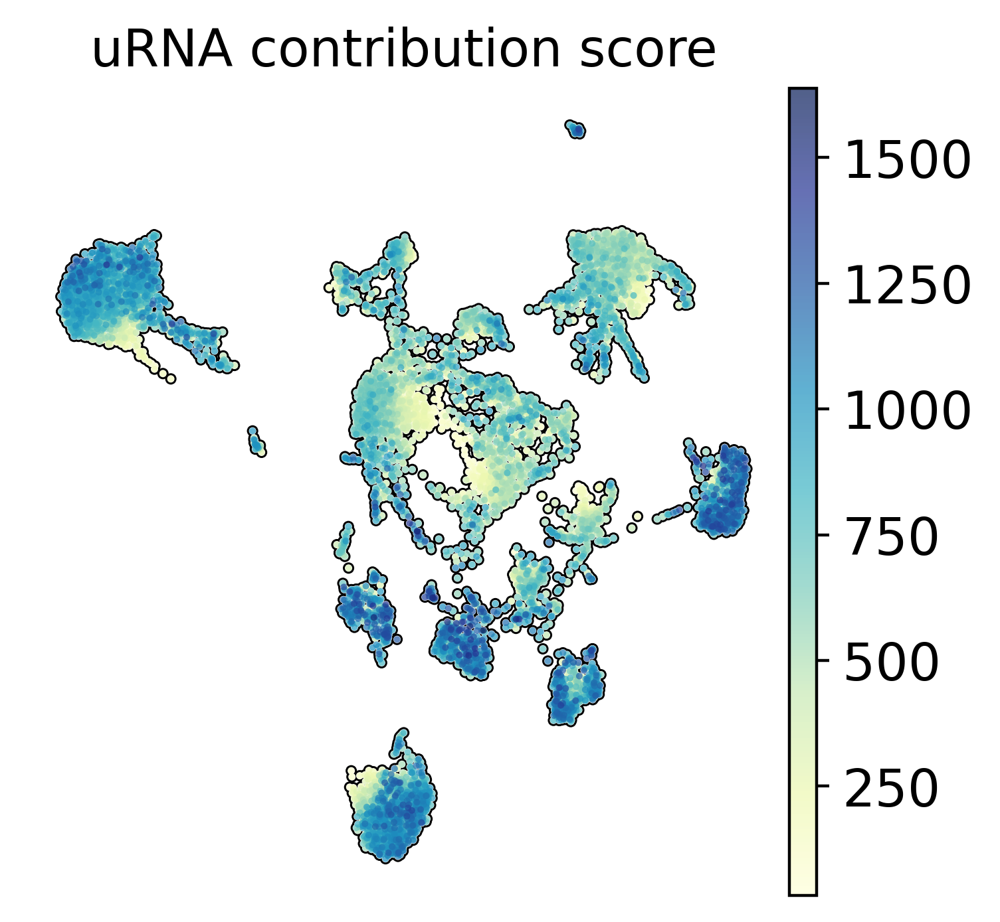

In [51]:
import matplotlib
# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

sc.set_figure_params(scanpy=True, dpi=200, dpi_save=200, frameon=True, vector_friendly=True, fontsize=14, figsize=None, color_map=None, format='pdf', facecolor=None, transparent=False, ipython_format='retina')
sc.pl.umap(sdata['table'],color='urna_contribution_score',cmap='YlGnBu',add_outline=True,frameon=False,title='uRNA contribution score',show=False)

In [52]:
sdata['table'].uns['cell_type_colors'] = [
    "#0FCCAC",   # Aqua Teal – bright and fresh, great for highlighting
    "#ED2073",   # Vivid Magenta Pink – strong contrast, eye-catching
    "#ebb434", 
    "#BFCE00",   # Chartreuse Green – light, acidic green, good for uncommon categories
    "#DF5AFF",   # Electric Purple – vibrant, stands out, ideal for rare cell types
    "#FC911D",   # Vivid Orange – warm and bold, useful for attention-grabbing
    "#E891B4",   # Pastel Rose – soft and gentle, good for subtle categories
    "#eb3d34",   # Mint Cream – pale green, useful for background or low-contrast layers
    "#37BEE2",   # Bright Sky Blue – vibrant and energetic, visually accessible
    "#790DB7",   # Royal Purple – deep and rich, contrasts well with yellows and greens
    "#ff69f7",   # Lime Green – bold but not neon, works well for active states
    "#43FBFF",   # Neon Cyan – very bright, best with dark backgrounds
    "#F7C894",   # Peach – soft and neutral, ideal for subtle cell states
    "#BCBCBC",   # Medium Gray – neutral, useful as a baseline or control color
    "#5cc460",   # Charcoal – strong neutral, works well for text or background
    "#9CFFFC",
    "#123755",   # Deep Navy Blue – dark and cool, good background or strong category
    "#FFFF7B",   # Soft Lemon Yellow – light and readable on dark backgrounds
]

coldict=dict(zip(np.unique(sdata['table'].obs['cell_type']),sdata['table'].uns['cell_type_colors']))

cols=[coldict[o] for o in order_selected]

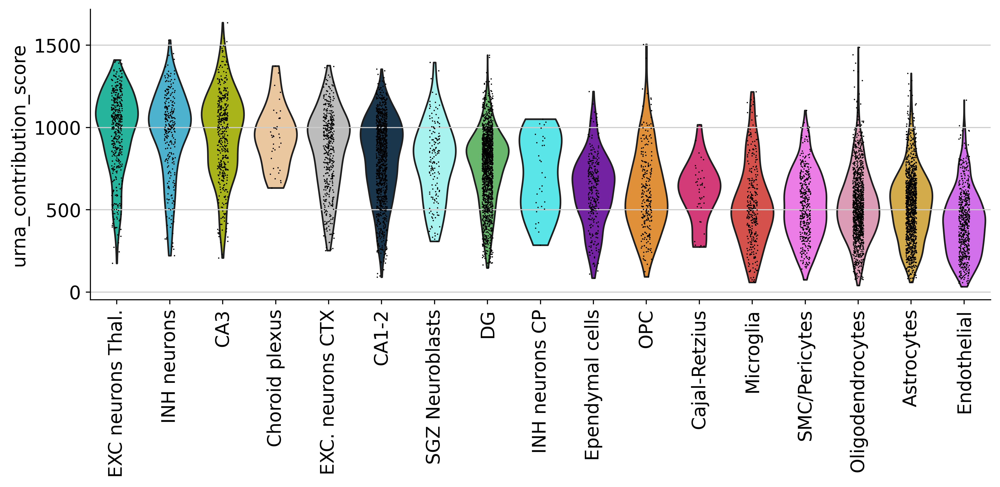

In [53]:
import matplotlib
import matplotlib.pyplot as plt
# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
sc.set_figure_params(scanpy=True, dpi=200, dpi_save=200, frameon=True, vector_friendly=True, fontsize=14, figsize=(10,4), color_map=None, format='pdf', facecolor=None, transparent=False, ipython_format='retina')

# Select order
order_selected=sdata['table'].obs.loc[:,['urna_contribution_score','cell_type']].groupby('cell_type').mean().sort_values(by='urna_contribution_score',ascending=False).index

# Your violin plot
sc.pl.violin(
    sdata['table'],
    'urna_contribution_score',
    groupby='cell_type',
    rotation=90,
    palette=cols,
    show=False,
    order=order_selected
)

# Remove outer box (spines)
ax = plt.gca()
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)


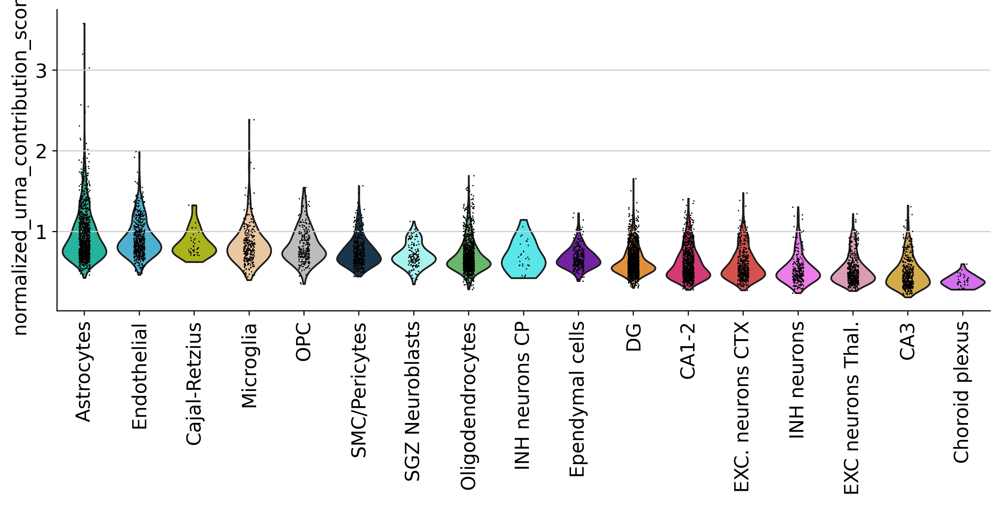

In [57]:
import matplotlib
import matplotlib.pyplot as plt
# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
sc.set_figure_params(scanpy=True, dpi=200, dpi_save=200, frameon=True, vector_friendly=True, fontsize=14, figsize=(10,4), color_map=None, format='pdf', facecolor=None, transparent=False, ipython_format='retina')

# Select order
order_selected=sdata['table'].obs.loc[:,['normalized_urna_contribution_score','cell_type']].groupby('cell_type').mean().sort_values(by='normalized_urna_contribution_score',ascending=False).index

# Your violin plot
sc.pl.violin(
    sdata['table'],
    'normalized_urna_contribution_score',
    groupby='cell_type',
    rotation=90,
    palette=cols,
    show=False,
    order=order_selected
)

# Remove outer box (spines)
ax = plt.gca()
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)


<Axes: title={'center': 'Normalized_uRNA contribution score'}, xlabel='UMAP1', ylabel='UMAP2'>

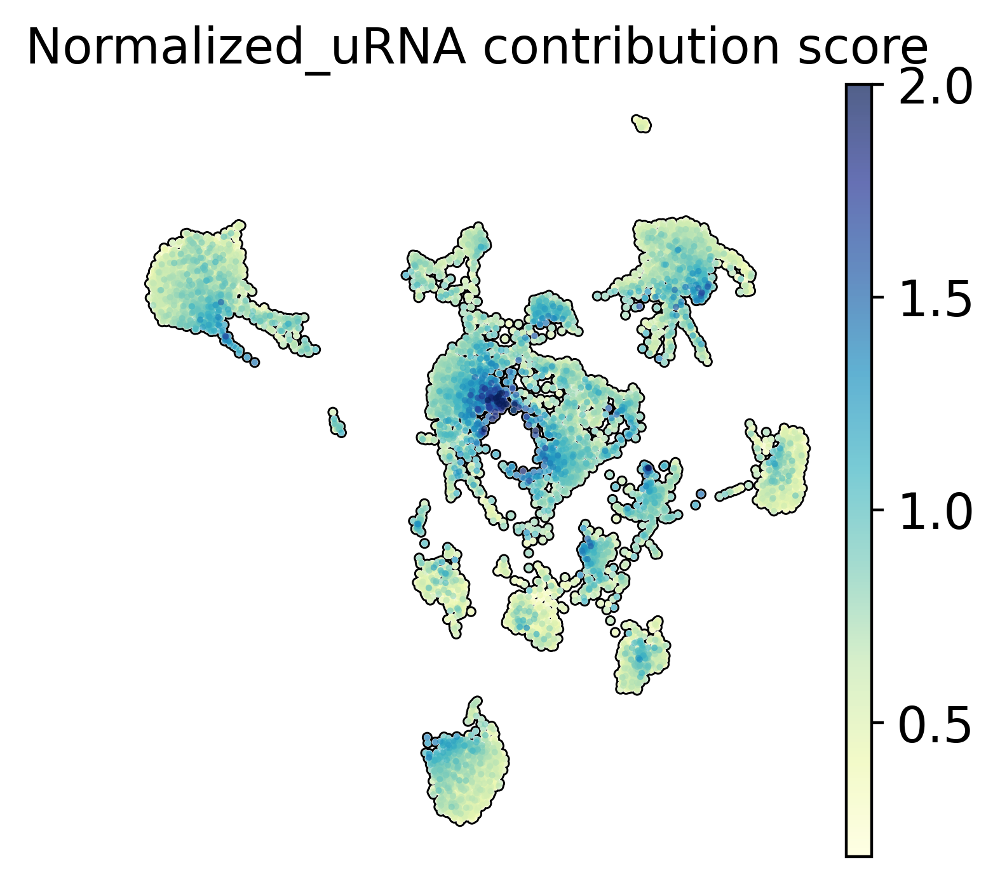

In [48]:

sc.set_figure_params(scanpy=True, dpi=200, dpi_save=200, frameon=True, vector_friendly=True, fontsize=14, figsize=None, color_map=None, format='pdf', facecolor=None, transparent=False, ipython_format='retina')
sc.pl.umap(sdata['table'],color='normalized_urna_contribution_score',cmap='YlGnBu',add_outline=True,frameon=False,title='Normalized_uRNA contribution score',show=False,vmax=2)

In [58]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

def plot_urna_vs_expression_proportion(sdata, top_n_labels=10, figsize=(7, 5), label_size=8):
    """
    Scatter plot of uRNA count vs. proportion of cells expressing each gene.

    Parameters
    ----------
    sdata : dict
        SpatialData object with 'table' (AnnData) and 'xrna_metadata' (with .var['count']).
    top_n_labels : int
        Number of top genes to label on each axis.
    figsize : tuple
        Size of the figure.
    label_size : int
        Font size for the gene labels.
    """
    adata = sdata["table"]
    gene_meta = sdata["xrna_metadata"].var

    raw_expr = adata.layers["raw"]
    if hasattr(raw_expr, "toarray"):
        raw_expr = raw_expr.toarray()

    genes = adata.var_names
    gene_meta = gene_meta.loc[gene_meta.index.intersection(genes)]
    if gene_meta.empty:
        raise ValueError("No common genes found between adata and metadata.")

    common_genes = gene_meta.index
    gene_indices = [adata.var_names.get_loc(g) for g in common_genes]
    raw_expr = raw_expr[:, gene_indices]  # (n_cells, n_common_genes)
    gene_meta = gene_meta.loc[common_genes]

    # Compute metrics
    urna_counts = gene_meta["count"].values
    expr_fraction = (raw_expr > 0).sum(axis=0) / raw_expr.shape[0]

    df = pd.DataFrame({
        "gene": common_genes,
        "uRNA_count": urna_counts,
        "expr_fraction": expr_fraction
    })

    # Plot
    fig, ax = plt.subplots(figsize=figsize)
    ax.scatter(df["expr_fraction"], df["uRNA_count"], alpha=0.7)
    ax.set_xlabel("Proportion of cells expressing gene")
    ax.set_ylabel("uRNA count")
    ax.set_title("uRNA amount vs. expression prevalence")

    # Annotate top genes on each axis
    label_genes = set()

    top_y = df.nlargest(top_n_labels, "uRNA_count")["gene"]
    top_x = df.nlargest(top_n_labels, "expr_fraction")["gene"]
    label_genes.update(top_y)
    label_genes.update(top_x)

    for _, row in df[df["gene"].isin(label_genes)].iterrows():
        ax.text(row["expr_fraction"], row["uRNA_count"], row["gene"],
                fontsize=label_size, ha="right", va="bottom")

    plt.tight_layout()
    plt.show()


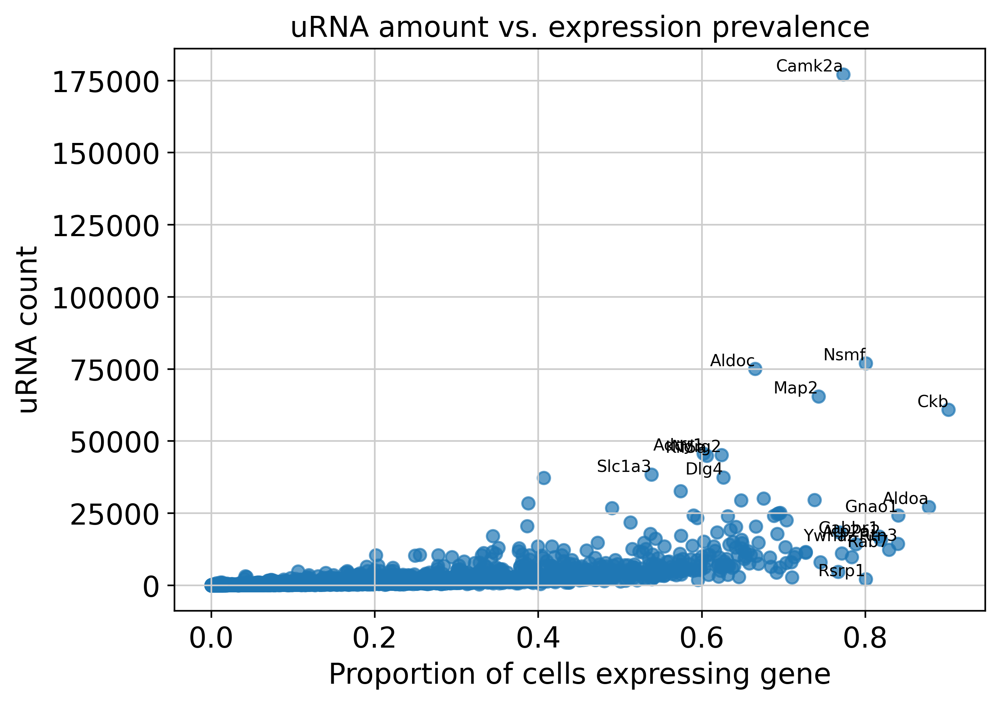

In [59]:
plot_urna_vs_expression_proportion(sdata, top_n_labels=10)

In [62]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

def plot_urna_vs_celltype_specificity(sdata, top_n_labels=10, figsize=(7, 5), label_size=8):
    """
    Scatter plot of uRNA count vs. number of cell types in which a gene is expressed.

    Parameters
    ----------
    sdata : dict
        SpatialData object with 'table' (AnnData) and 'xrna_metadata' (with .var['count']).
    top_n_labels : int
        Number of top genes to label on each axis.
    figsize : tuple
        Size of the figure.
    label_size : int
        Font size for the gene labels.
    """
    adata = sdata["table"]
    gene_meta = sdata["xrna_metadata"].var
    raw_expr = adata.layers["raw"]
    if hasattr(raw_expr, "toarray"):
        raw_expr = raw_expr.toarray()

    if "cell_type" not in adata.obs:
        raise ValueError("Missing 'cell_type' column in adata.obs.")

    genes = adata.var_names
    gene_meta = gene_meta.loc[gene_meta.index.intersection(genes)]
    if gene_meta.empty:
        raise ValueError("No common genes found between adata and metadata.")

    common_genes = gene_meta.index
    gene_indices = [adata.var_names.get_loc(g) for g in common_genes]
    raw_expr = raw_expr[:, gene_indices]
    gene_meta = gene_meta.loc[common_genes]

    # Get unique cell types
    cell_types = adata.obs["cell_type"].astype(str)
    unique_cell_types = cell_types.unique()
    n_celltypes = len(unique_cell_types)

    # Compute cell type specificity
    celltype_specificity = []
    for i in range(raw_expr.shape[1]):
        expr = raw_expr[:, i]
        expr_df = pd.DataFrame({
            "expr": expr,
            "cell_type": cell_types.values
        })
        expressed_celltypes = expr_df.groupby("cell_type")["expr"].apply(lambda x: (x > 10).any())
        n_expressing_celltypes = expressed_celltypes.sum()
        celltype_specificity.append(n_expressing_celltypes)

    # Make plot data
    df = pd.DataFrame({
        "gene": common_genes,
        "uRNA_count": gene_meta["count"].values,
        "n_celltypes_expressing": celltype_specificity
    })

    # Plot
    fig, ax = plt.subplots(figsize=figsize)
    ax.scatter(df["n_celltypes_expressing"], df["uRNA_count"], alpha=0.7)
    ax.set_xlabel("Number of cell types expressing gene")
    ax.set_ylabel("uRNA count")
    ax.set_title("uRNA vs. cell type specificity")

    # Label top genes
    label_genes = set()
    top_y = df.nlargest(top_n_labels, "uRNA_count")["gene"]
    top_x = df.nsmallest(top_n_labels, "n_celltypes_expressing")["gene"]
    label_genes.update(top_y)
    label_genes.update(top_x)

    for _, row in df[df["gene"].isin(label_genes)].iterrows():
        ax.text(row["n_celltypes_expressing"], row["uRNA_count"], row["gene"],
                fontsize=label_size, ha="right", va="bottom")

    plt.tight_layout()
    plt.show()


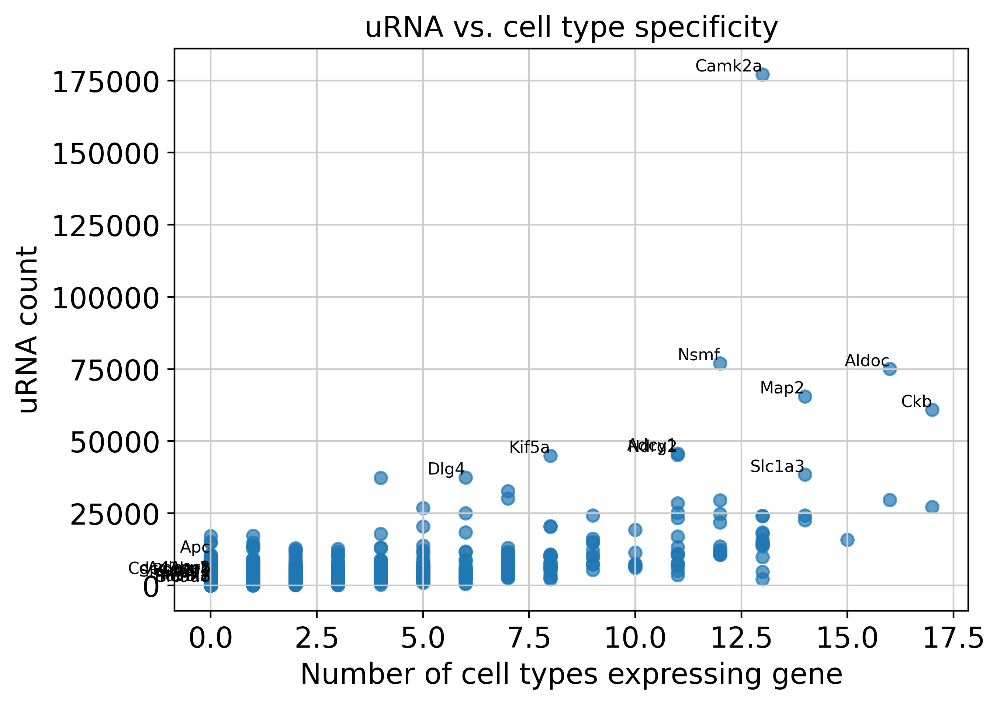

In [63]:
plot_urna_vs_celltype_specificity(sdata, top_n_labels=10, figsize=(7, 5), label_size=8)

In [3]:
troutpy.tl.compute_contribution_score(sdata)

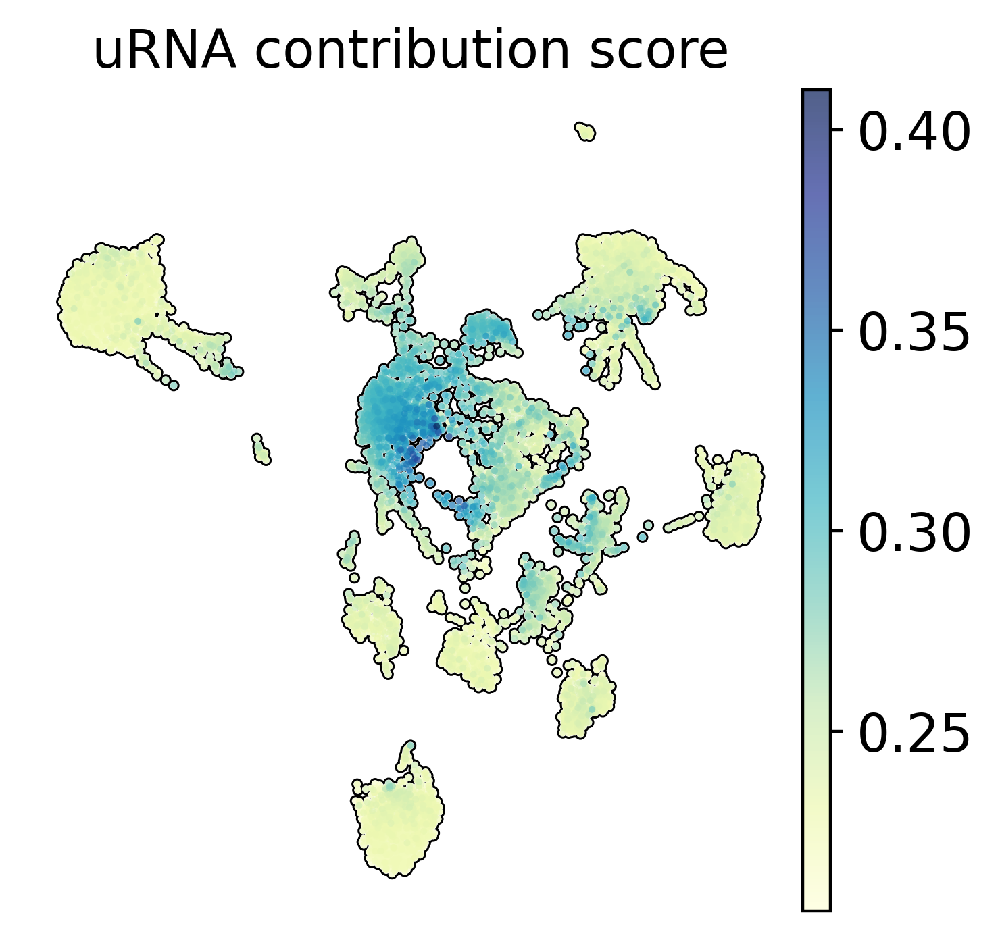

In [40]:
import matplotlib
# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

sc.set_figure_params(scanpy=True, dpi=200, dpi_save=200, frameon=True, vector_friendly=True, fontsize=14, figsize=None, color_map=None, format='pdf', facecolor=None, transparent=False, ipython_format='retina')
sc.pl.umap(sdata['table'],color='urna_contribution_score',cmap='YlGnBu',add_outline=True,frameon=False,title='uRNA contribution score',show=False)
plt.savefig(os.path.join(saving_path,'cells_umap_contribution_score.pdf'))

<Axes: title={'center': 'cell_type'}, xlabel='UMAP1', ylabel='UMAP2'>

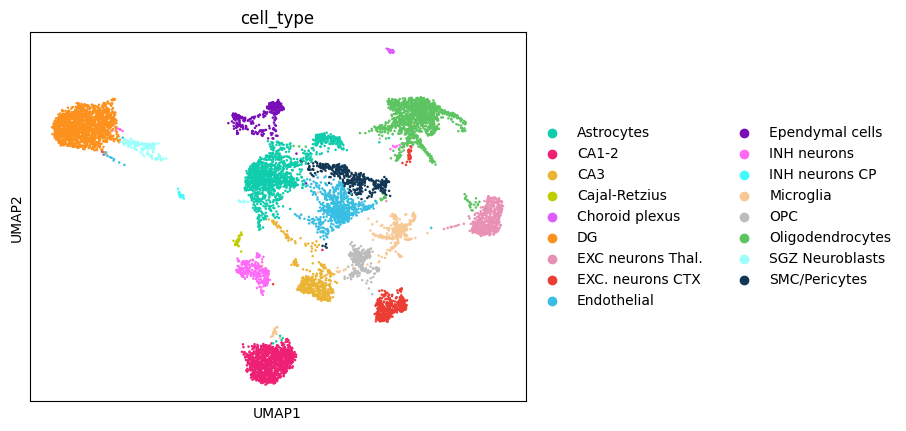

In [37]:
sdata['table'].uns['cell_type_colors'] = [
    "#0FCCAC",   # Aqua Teal – bright and fresh, great for highlighting
    "#ED2073",   # Vivid Magenta Pink – strong contrast, eye-catching
    "#ebb434", 
    "#BFCE00",   # Chartreuse Green – light, acidic green, good for uncommon categories
    "#DF5AFF",   # Electric Purple – vibrant, stands out, ideal for rare cell types
    "#FC911D",   # Vivid Orange – warm and bold, useful for attention-grabbing
    "#E891B4",   # Pastel Rose – soft and gentle, good for subtle categories
    "#eb3d34",   # Mint Cream – pale green, useful for background or low-contrast layers
    "#37BEE2",   # Bright Sky Blue – vibrant and energetic, visually accessible
    "#790DB7",   # Royal Purple – deep and rich, contrasts well with yellows and greens
    "#ff69f7",   # Lime Green – bold but not neon, works well for active states
    "#43FBFF",   # Neon Cyan – very bright, best with dark backgrounds
    "#F7C894",   # Peach – soft and neutral, ideal for subtle cell states
    "#BCBCBC",   # Medium Gray – neutral, useful as a baseline or control color
    "#5cc460",   # Charcoal – strong neutral, works well for text or background
    "#9CFFFC",
    "#123755",   # Deep Navy Blue – dark and cool, good background or strong category
    "#FFFF7B",   # Soft Lemon Yellow – light and readable on dark backgrounds
]
sc.pl.umap(sdata['table'],color='cell_type',show=False)

In [84]:
coldict=dict(zip(np.unique(sdata['table'].obs['cell_type']),sdata['table'].uns['cell_type_colors']))

cols=[coldict[o] for o in order_selected]

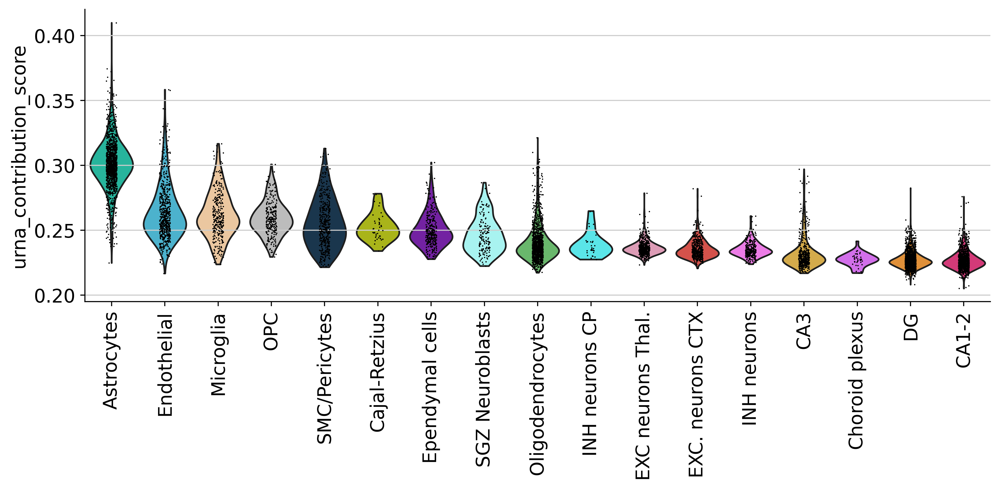

In [85]:
import matplotlib
import matplotlib.pyplot as plt
# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
sc.set_figure_params(scanpy=True, dpi=200, dpi_save=200, frameon=True, vector_friendly=True, fontsize=14, figsize=(10,4), color_map=None, format='pdf', facecolor=None, transparent=False, ipython_format='retina')

# Select order
order_selected=sdata['table'].obs.loc[:,['urna_contribution_score','cell_type']].groupby('cell_type').mean().sort_values(by='urna_contribution_score',ascending=False).index

# Your violin plot
sc.pl.violin(
    sdata['table'],
    'urna_contribution_score',
    groupby='cell_type',
    rotation=90,
    palette=cols,
    show=False,
    order=order_selected
)

# Remove outer box (spines)
ax = plt.gca()
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(saving_path,'cells_violin_contribution_score.pdf'))


# Now we compute source score

In [67]:
import warnings

import numpy as np
import pandas as pd
import scanpy as sc
import spatialdata as sd
from joblib import Parallel, delayed
from scipy.spatial import cKDTree
from sklearn.neighbors import KDTree
from spatialdata import SpatialData
from tqdm import tqdm



def compute_source_score(
    sdata,
    layer: str = "transcripts",
    gene_key: str = "gene",
    coord_keys: list = None,
    lambda_decay: float = 0.1,
    copy: bool = False,
    celltype_key: str = "cell type",
    n_jobs: int = -1,
):
    """
    Compute a source score for extracellular transcripts based on nearby cell types and gene expression profiles, using exponential distance decay.

    Parameters
    ----------
    sdata : spatialdata.SpatialData
        SpatialData object with a transcript layer and an AnnData table.
    layer : str
        Name of the layer in sdata.points containing transcripts. Default is "transcripts".
    gene_key : str
        Column name in transcript table corresponding to gene names. Default is "gene".
    coord_keys : list
        List of coordinate column names to use (e.g., ["x", "y"]). Default is ["x", "y"].
    lambda_decay : float
        Decay rate for the exponential function applied to distances. Default is 0.1.
    copy : bool
        If True, return a copy of the SpatialData object with results added. Default is False.
    celltype_key : str
        Column name in adata.obs specifying cell type labels. Default is "cell type".
    n_jobs : int
        Number of parallel jobs to run (-1 uses all processors). Default is -1.

    Returns
    -------
    SpatialData or None
        Updated SpatialData object with added transcript-level and cell-level source scores.
        Returns None if copy=False (modifies sdata in place).
    """
    if coord_keys is None:
        coord_keys = ["x", "y"]
    xcoord, ycoord = coord_keys[:2]

    transcripts = sdata.points[layer].compute()
    adata = sdata["table"]
    coord_cells = adata.obsm["spatial"]

    cells = extract_expression_matrix(adata)
    cell_types = adata.obs[celltype_key]
    all_cell_types = cell_types.unique()

    extracellular_transcripts = get_extracellular_transcripts(transcripts)

    genes_to_process = extracellular_transcripts[gene_key].unique()

    results = Parallel(n_jobs=n_jobs)(
        delayed(process_gene)(gene, extracellular_transcripts, cells, coord_cells, cell_types, gene_key, xcoord, ycoord, lambda_decay, all_cell_types)
        for gene in tqdm(genes_to_process, desc="Processing genes")
    )

    probabilities_table, closet_cell_table, cell_source_table = build_result_tables(
        results, extracellular_transcripts, adata, genes_to_process, all_cell_types
    )

    store_results_in_sdata(sdata, probabilities_table, closet_cell_table, extracellular_transcripts, xcoord, ycoord, gene_key, cell_source_table)

    return sdata.copy() if copy else None


def extract_expression_matrix(adata):
    """Extract expression matrix from AnnData object."""
    return pd.DataFrame(
        adata.X.toarray() if hasattr(adata.X, "toarray") else adata.X,
        index=adata.obs_names,
        columns=adata.var_names,
    )


def get_extracellular_transcripts(transcripts):
    """Filter for extracellular transcripts."""
    if "extracellular" not in transcripts.columns:
        raise ValueError("Column 'extracellular' missing from transcript table.")
    extracellular_transcripts = transcripts[transcripts["extracellular"]]
    if extracellular_transcripts.empty:
        raise ValueError("No extracellular transcripts found.")
    return extracellular_transcripts


def process_gene(gene, extracellular_transcripts, cells, coord_cells, cell_types, gene_key, xcoord, ycoord, lambda_decay, all_cell_types):
    """Process a single gene to compute transcript scores and closest cells."""
    gene_transcripts = extracellular_transcripts[extracellular_transcripts[gene_key] == gene]
    if gene not in cells.columns:
        return None

    gene_mask = cells[gene] > 0
    if not gene_mask.any() or gene_transcripts.empty:
        return None

    gene_cells = cells.loc[gene_mask]
    coord_cells_filt = coord_cells[gene_mask]
    cell_types_filt = cell_types[gene_mask]
    transcript_coords = gene_transcripts[[xcoord, ycoord]].to_numpy()

    tree = cKDTree(coord_cells_filt)
    distances, cell_indices = tree.query(transcript_coords, k=len(gene_cells))

    distances_min = distances[:, 0]
    closest_idxs = cell_indices[:, 0]
    closest_cell_ids = gene_cells.index[closest_idxs].to_numpy()
    closest_cell_types = cell_types_filt.iloc[closest_idxs].to_numpy()

    cell_exprs = gene_cells[gene].to_numpy()
    exp_decay = np.exp(-lambda_decay * distances)
    scores = exp_decay * cell_exprs[cell_indices]

    ### this part
    residual = 1e-6  # small stabilizing term
    row_sums = scores.sum(axis=1, keepdims=True) + residual
    scores = scores / row_sums
    #scores=scores.div(scores.sum(axis=1),axis=0)

    gene_prob_df = compute_probability_table(scores, cell_indices, cell_types_filt, all_cell_types, gene_transcripts)
    gene_closest_df = build_closest_cell_table(distances_min, closest_cell_ids, closest_cell_types, gene_transcripts)
    gene_by_cell_scores = sum_scores_per_cell(gene_cells, scores, cell_indices)

    return gene_prob_df, gene_closest_df, gene_by_cell_scores


def compute_probability_table(scores, cell_indices, cell_types_filt, all_cell_types, gene_transcripts):
    """Build transcript-by-celltype score probability table."""
    n_transcripts = len(gene_transcripts)
    prob_results = np.zeros((n_transcripts, len(all_cell_types)), dtype=float)
    cell_type_to_idx = {ct: i for i, ct in enumerate(all_cell_types)}

    for i in range(n_transcripts):
        types_i = cell_types_filt.iloc[cell_indices[i]].to_numpy()
        scores_i = scores[i]
        type_indices = np.array([cell_type_to_idx[t] for t in types_i])
        score_sum = np.bincount(type_indices, weights=scores_i, minlength=len(all_cell_types))
        prob_results[i, :] = score_sum

    return pd.DataFrame(prob_results, index=gene_transcripts.index, columns=all_cell_types)


def build_closest_cell_table(distances, closest_cell_ids, closest_cell_types, gene_transcripts):
    """Construct DataFrame with closest cell and cell type info."""
    return pd.DataFrame(
        {"distance": distances, "closest_cell": closest_cell_ids, "closest_celltype": closest_cell_types},
        index=gene_transcripts.index,
    )


def sum_scores_per_cell(gene_cells, scores, cell_indices):
    """Aggregate transcript scores per cell."""
    all_cell_ids = gene_cells.index.to_numpy()
    gene_by_cell_scores = pd.Series(0.0, index=all_cell_ids)

    for i in range(len(scores)):
        cell_idx_i = cell_indices[i]
        scores_i = scores[i]
        cell_ids_i = gene_cells.index[cell_idx_i]
        gene_by_cell_scores[cell_ids_i] += scores_i

    return gene_by_cell_scores


def build_result_tables(results, extracellular_transcripts, adata, genes_to_process, all_cell_types):
    """Initialize and fill summary tables for all genes."""
    prob_table = pd.DataFrame(0, index=extracellular_transcripts.index, columns=all_cell_types, dtype=float)
    closest_table = pd.DataFrame(0, index=extracellular_transcripts.index, columns=["closest_cell", "closest_celltype", "distance"])
    cell_score_table = pd.DataFrame(0, index=adata.obs_names, columns=genes_to_process)

    for i, res in enumerate(results):
        if res is None:
            continue
        gene_prob_df, gene_closest_df, gene_by_cell_df = res
        prob_table.loc[gene_prob_df.index, :] = gene_prob_df
        closest_table.loc[gene_closest_df.index, :] = gene_closest_df
        cell_score_table.loc[gene_by_cell_df.index, genes_to_process[i]] = gene_by_cell_df.values.flatten()

    return prob_table, closest_table, cell_score_table


def store_results_in_sdata(sdata, prob_table, closest_table, extracellular_transcripts, xcoord, ycoord, gene_key, cell_source_table):
    """Store transcript- and cell-level results in the sdata object."""
    prob_adata = sc.AnnData(prob_table)
    prob_adata.obs[gene_key] = extracellular_transcripts[gene_key].values
    prob_adata.obs["distance"] = closest_table["distance"].astype(float).values
    prob_adata.obs["closest_cell"] = closest_table["closest_cell"].astype(str).values
    prob_adata.obs["closest_celltype"] = closest_table["closest_celltype"].astype(str).values
    prob_adata.obsm["spatial"] = extracellular_transcripts[[xcoord, ycoord]].to_numpy()
    sdata.tables["source_score"] = prob_adata

    sdata["table"].obs["urna_source_score"] = list(np.sum(cell_source_table, axis=1))

In [ ]:
compute_source_score(sdata, layer="transcripts", gene_key="gene", lambda_decay=0.1, copy=False, celltype_key="cell_type",n_jobs=4)

Processing genes:  33%|███████████████████▏                                       | 1396/4279 [54:02<1:29:26,  1.86s/it]

Now we save the results as a zarr, since computing source score takes a while

In [ ]:
sdata.write("/media/sergio/Meninges/troutpy/rois/xenium_msbrain_5k/data_processed_with_scores.zarr")#"/media/sergio/Meninges/troutpy/rois/xenium_mscolon_5k/data_processed_filtered.zarr")

# Source score metric- plots

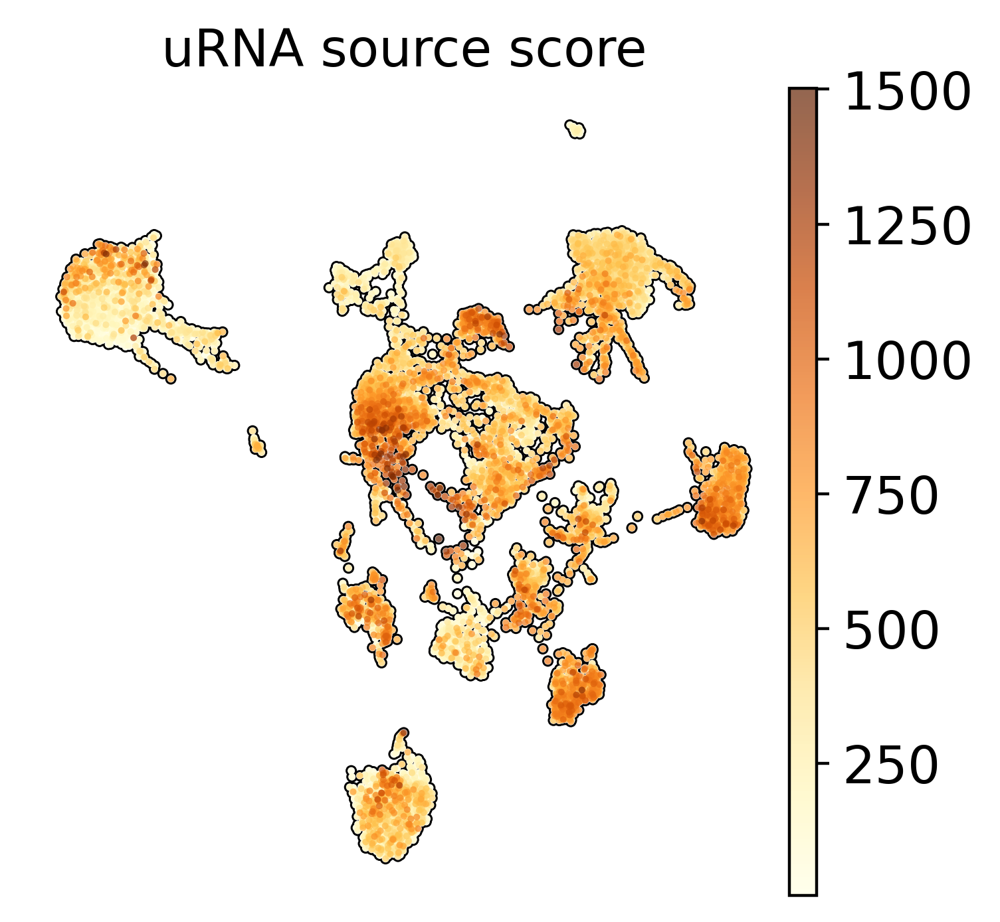

In [81]:
import matplotlib
# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

sc.set_figure_params(scanpy=True, dpi=200, dpi_save=200, frameon=True, vector_friendly=True, fontsize=14, figsize=None, color_map=None, format='pdf', facecolor=None, transparent=False, ipython_format='retina')
sc.pl.umap(sdata['table'],color='urna_source_score',cmap='YlOrBr',add_outline=True,frameon=False,title='uRNA source score',show=False,vmax='p99.995')
plt.savefig(os.path.join(saving_path,'cells_umap_source_score.pdf'))

In [7]:
adata=sdata['table']

In [22]:
adata.obs['urna_source_score_norm']=adata.obs['urna_source_score']/adata.obs['total_counts']

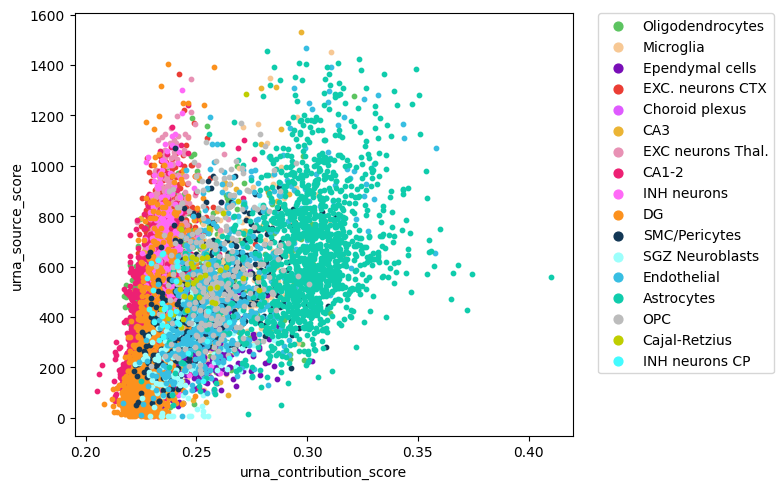

In [27]:
import matplotlib.pyplot as plt
import numpy as np

# Create the color dictionary
coldict = dict(zip(
    np.unique(sdata['table'].obs['cell_type']),
    sdata['table'].uns['cell_type_colors']
))

plt.figure(figsize=(8, 5))

for cell_type in sdata['table'].obs['cell_type'].unique():
    subset = sdata['table'].obs[sdata['table'].obs['cell_type'] == cell_type]
    plt.scatter(
        subset['urna_contribution_score'],
        subset['urna_source_score'],
        s=10,
        color=coldict[cell_type],
        label=cell_type,
        alpha=1
    )

plt.xlabel('urna_contribution_score')
plt.ylabel('urna_source_score')
plt.legend(markerscale=2, bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.tight_layout()
plt.show()


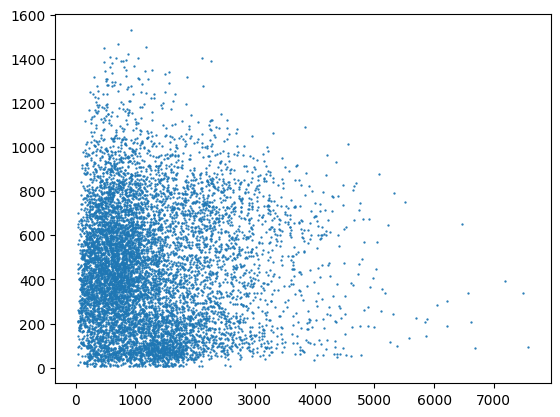

In [12]:
plt.scatter(adata.obs['total_counts'],adata.obs['urna_source_score'],s=0.4)
plt.xlabel('Total cell counts')
plt.ylabel('Urna_source_score')

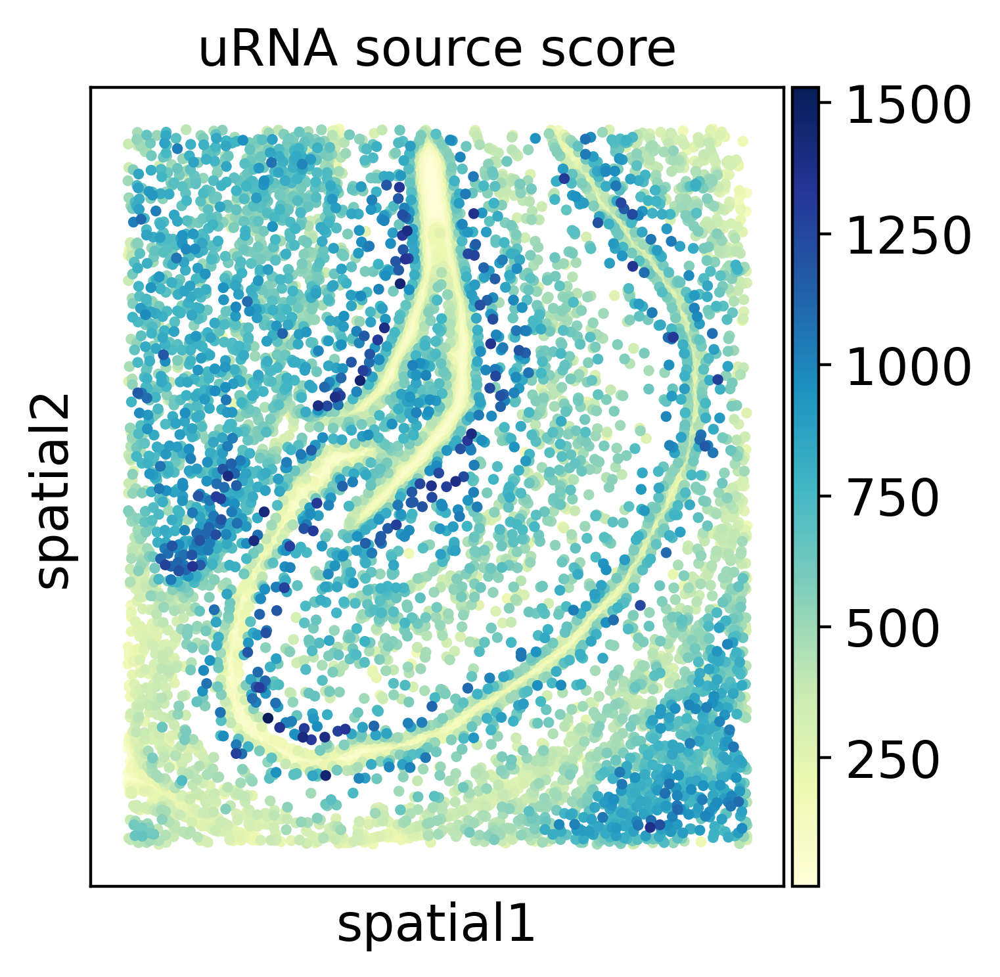

In [71]:
sc.pl.spatial(sdata['table'],color='urna_source_score',cmap='YlGnBu',spot_size=30,title='uRNA source score')

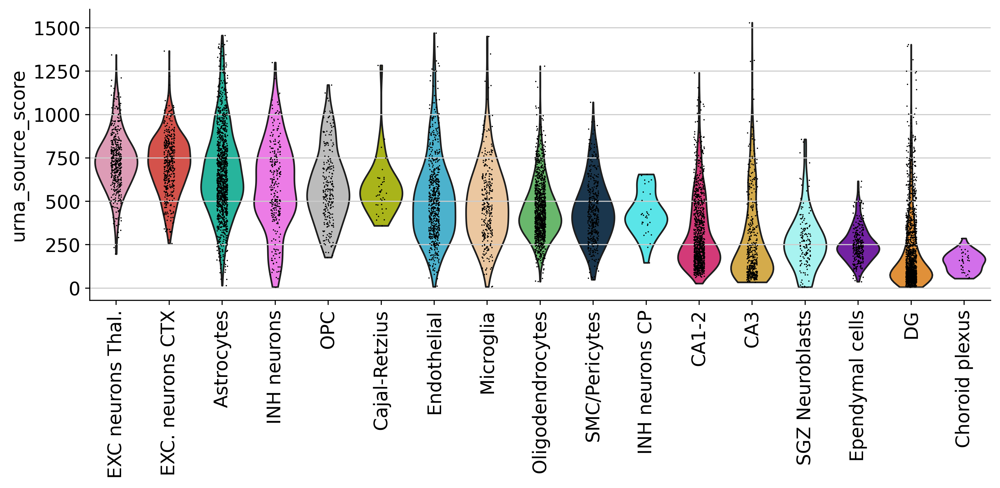

In [86]:
import matplotlib
import matplotlib.pyplot as plt
# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
sc.set_figure_params(scanpy=True, dpi=200, dpi_save=200, frameon=True, vector_friendly=True, fontsize=14, figsize=(10,4), color_map=None, format='pdf', facecolor=None, transparent=False, ipython_format='retina')

# Select order
order_selected=sdata['table'].obs.loc[:,['urna_source_score','cell_type']].groupby('cell_type').mean().sort_values(by='urna_source_score',ascending=False).index
cols=[coldict[o] for o in order_selected]
# Your violin plot
sc.pl.violin(
    sdata['table'],
    'urna_source_score',
    groupby='cell_type',
    rotation=90,
    palette=cols,
    show=False,
    order=order_selected
)

# Remove outer box (spines)
ax = plt.gca()
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(saving_path,'cells_violin_source_score.pdf'))


# Comparison of contribution score vs source score

[<Axes: title={'center': 'uRNA source score'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'urna_contribution_score'}, xlabel='UMAP1', ylabel='UMAP2'>]

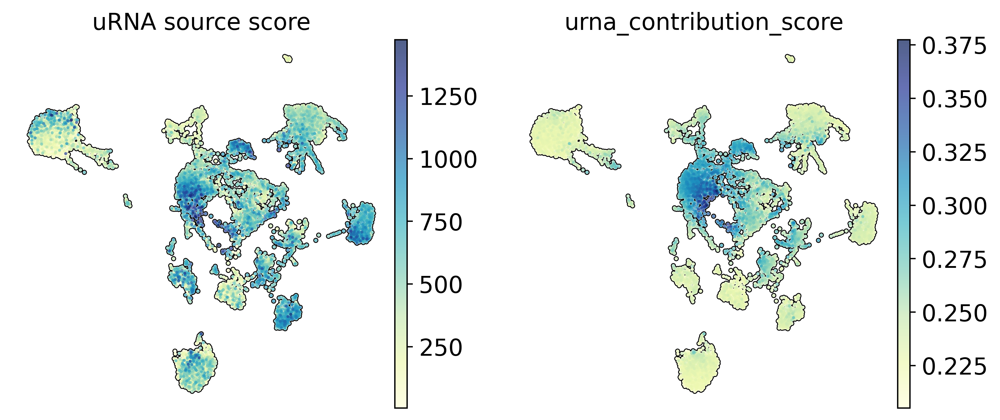

In [75]:
import matplotlib
# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

sc.set_figure_params(scanpy=True, dpi=200, dpi_save=200, frameon=True, vector_friendly=True, fontsize=14, figsize=None, color_map=None, format='pdf', facecolor=None, transparent=False, ipython_format='retina')
sc.pl.umap(sdata['table'],color=['urna_source_score','urna_contribution_score'],vmax='p99.99',cmap='YlGnBu',add_outline=True,frameon=False,title='uRNA source score',show=False)

# Target score

In [82]:
troutpy.tl.compute_target_score(sdata,layer="transcripts",lambda_decay=0.1,copy=False,celltype_key="leiden",gene_key='gene')

MemoryError: Unable to allocate 428. GiB for an array with shape (6260348, 9185) and data type float64

In [ ]:
troutpy.pl.target_score_by_celltype(sdata, figsize=(5, 5),gene_key='gene')

In [ ]:
sc.pl.umap(sdata['table'],color='total_counts',cmap='coolwarm',s=20)

In [ ]:
sc.pl.umap(sdata['table'],color='leiden',cmap='coolwarm',s=20)

In [ ]:
sc.pl.umap(sdata['table'],color='urna_source_score',cmap='coolwarm',s=50,vmax='p99.5')

In [ ]:
sc.set_figure_params( scanpy=True, dpi=80, dpi_save=150, frameon=True, vector_friendly=True, fontsize=14, figsize=(10,10), color_map=None, format='pdf', facecolor=None, transparent=False, ipython_format='retina')


plt.figure(figsize=(20,20))
sc.pl.spatial(sdata['table'],color='urna_source_score',cmap='coolwarm',spot_size=70,vmax='p99.5')

In [ ]:
compute_contribution_score(sdata)

In [ ]:
sc.pl.umap(sdata['table'],color=['urna_source_score',"urna_contribution_score"],cmap='coolwarm',s=200,vmax='p99.9')

In [ ]:
compute_source_score(sdata, layer="transcripts", gene_key="gene", lambda_decay=0.1, copy=False, celltype_key="leiden",n_jobs=4)

In [ ]:
sc.pl.umap(sdata['table'],color=['source_score_sum',"projection_score"],cmap='coolwarm',s=20,vmax='p99.5')

In [ ]:
plt.scatter(sdata['table'].obs['source_score_sum'],sdata['table'].obs['projection_score'],s=0.2)

In [ ]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns
import spatialdata as sd  # Assuming this is the correct import
from spatialdata import SpatialData  # Assuming this is the correct import



def global_distribution_from_source(
    sdata: SpatialData,
    cool_pattern,
    gene_key: str = "gene",
    distance_key: str = "distance",
    bins: int = 30,
    bar_color: str = "lightblue",
    n_cols: int = 3,
):
    """
    Plots the diffusion distribution of specified genes as subplots in a grid.

    Parameters
    ----------
    sdata: spatialdata.SpatialData
        The spatial dataset containing gene expression and diffusion data.
    cool_pattern: list
        List of gene names to analyze.
    gene_key: str
        Column name for gene features (default: 'gene').
    distance_key: str
        Column name for distance values (default: 'distance').
    bins: int
        Number of bins for histogram (default: 30).
    bar_color: str
        Color of histogram bars (default: 'lightblue').
    n_cols: int
        Number of columns in the subplot grid (default: 3).

    Raises
    ------
        ValueError: If no valid genes are found in the dataset.
    """
    diffusion_results = sdata["xrna_metadata"].var
    global_distances = sdata["source_score"].obs[distance_key].dropna().values

    if len(global_distances) == 0:
        raise ValueError("No valid distance values found in the dataset.")

    # Filter out non-positive values (Rayleigh is defined only for x > 0)
    global_distances = global_distances[global_distances > 0]
    param = stats.rayleigh.fit(global_distances, floc=0)

    valid_genes = [gene for gene in cool_pattern if gene in diffusion_results.index]

    if not valid_genes:
        raise ValueError("No specified genes were found in the dataset.")

    n_genes = len(valid_genes)
    n_rows = math.ceil(n_genes / n_cols)  # Calculate required rows based on columns

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 4))
    axes = np.array(axes).reshape(-1)  # Flatten to make indexing easier

    for i, gene in enumerate(valid_genes):
        ax = axes[i]  # Select subplot

        try:
            distances = sdata["source_score"].obs[distance_key].dropna().values
            param_g = stats.rayleigh.fit(distances, floc=0)
            if len(distances) == 0:
                print(f"Warning: No valid distances found for gene {gene}, skipping.")
                continue

            x = np.linspace(0, max(global_distances), 500)
            y = stats.rayleigh.pdf(x, *param)

            x_g = np.linspace(0, max(distances), 500)
            y_g = stats.rayleigh.pdf(x_g, *param_g)

            sns.histplot(distances, bins=bins, stat="density", kde=False, color=bar_color, label="Empirical", ax=ax)
            ax.plot(x, y, "r-", label="Global Fitted Rayleigh")
            ax.plot(x_g, y_g, "b-", label="Gene Fitted Rayleigh")

            gene_stats = diffusion_results.loc[diffusion_results.index == gene].iloc[0]
            ax.set_title(f" Global distribution \nKS p-value: {gene_stats['ks_pval']:.3f}, LR Stat: {gene_stats['lr_stat']:.2f}")
            ax.set_xlabel("Distance")
            ax.set_ylabel("Density")
            ax.legend()

        except KeyError:
            KeyError(f"Error processing gene {gene}")

    # Remove any unused subplots if the number of genes is less than n_rows * n_cols
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])
    plt.xlim(0,200)
    plt.tight_layout()
    return fig,axes

In [ ]:
import matplotlib
import os

# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

fig,ax=global_distribution_from_source(sdata, selected_genes[1:2],bins=500)
plt.savefig(os.path.join(saving_path,'distribution_msbrain_diffussion.pdf'))

In [ ]:
# Technology 1: Xenium
sdata = sd.read_zarr("/media/sergio/Meninges/troutpy/rois/cosmx_mousebrain/data_processed_filtered.zarr")
saving_path='/media/sergio/Meninges/troutpy/figures'

In [ ]:
import matplotlib
import os

# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

fig,ax=global_distribution_from_source(sdata, selected_genes[1:2],bins=500)
plt.savefig(os.path.join(saving_path,'distribution_msbrain_cosmx_diffussion.pdf'))

In [ ]:
# Technology 1: Xenium
sdata = sd.read_zarr("/media/sergio/Meninges/troutpy/rois/xenium_hsskin_5k/data_processed_filtered.zarr")
saving_path='/media/sergio/Meninges/troutpy/figures'

In [ ]:
sdata['xrna_metadata'].var

In [ ]:
import matplotlib
import os

# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

fig,ax=global_distribution_from_source(sdata, ['VEGFB'] ,bins=500)
plt.savefig(os.path.join(saving_path,'distribution_xenium_hsskin_diffussion.pdf'))

# 1. Additional unimodal plots

In [ ]:
from matplotlib.colors import ListedColormap, Normalize
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.affinity import affine_transform
from shapely.geometry import box
import numpy as np
import pandas as pd


def spatial_transcripts(
    sdata: SpatialData,
    gene_key: str = "gene",
    gene_list: list[str] | None = None,
    color_key: str = "transcript_type",
    shapes_key: str = "cell_boundaries",
    colormap: str = "30colors",
    boundary_linewidth: float = 0.5,
    scatter_size: float = 1.0,
    alpha: float = 0.8,
    use_roi: bool = False,
    roi: tuple[float, float, float, float] = (0, 20000, 0, 20000),
    figsize: tuple[float, float] = (8, 8),
    title: str = "Cell Boundaries + Transcripts",
) -> tuple[plt.Figure, plt.Axes]:
    """
    Plot cell boundary polygons and transcript points, colored by a categorical variable
    or a numeric variable, scaling geometries by an affine matrix from get_transformation.

    Parameters
    ----------
    sdata
        A SpatialData object containing:
          - sdata[shapes_key]  including a 'geometry' column of shapely Polygons
          - sdata['transcripts'] including `gene_key` and `color_key`
    gene_key: str
        Column in transcripts to filter by gene_list.
    gene_list: Optional[List[str]]
        List of genes to keep. If None, all transcripts are used.
    color_key: str
        Column in transcripts used for coloring points. Can be categorical or numeric.
    shapes_key: str
        Key in sdata for your polygon boundaries layer.
    colormap: str
        Name of a Matplotlib colormap or troutpy palette name.
    boundary_linewidth: float
        Line width of cell boundary outlines.
    scatter_size: float
        Marker size for transcript points.
    alpha: float
        Transparency for transcript points.
    use_roi: bool
        If True, restrict both polygons and points to the bounding box given by `roi`.
    roi: Tuple[float, float, float, float]
        (xmin, xmax, ymin, ymax) bounds to clip to when `use_roi=True`.
    figsize: Tuple[float, float]
        Width and height of the figure.
    title: str
        Title string placed above the plot.

    Returns
    -------
    fig, ax
        The Matplotlib figure and axes objects.
    """
    # 1) Filter transcripts by gene_list
    trans_ad = sdata["transcripts"].compute()
    if gene_list is not None:
        trans_ad = trans_ad[trans_ad[gene_key].isin(gene_list)]

    # annotate transcript types
    trans_ad["segstatus"] = trans_ad["overlaps_cell"].astype(str) + "_" + trans_ad["extracellular"].astype(str)
    stat2lab = {"True_False": "cell", "False_True": "extracellular", "False_False": "cell-like"}
    trans_ad["transcript_type"] = trans_ad["segstatus"].map(stat2lab)

    # 2) Prepare color values based on type (categorical or numeric)
    trans_df = trans_ad.copy()
    if pd.api.types.is_numeric_dtype(trans_df[color_key]):
        is_numeric = True
        color_values = trans_df[color_key].astype(float)
        cmap = plt.get_cmap(colormap)
        norm = Normalize(vmin=color_values.min(), vmax=color_values.max())
    else:
        is_numeric = False
        cats = trans_df[color_key].astype("category")
        color_values = cats.cat.codes.values
        n_cats = len(cats.cat.categories)
        try:
            import troutpy
            pal = troutpy.pl.get_palette(colormap, n_cats)
            cmap = ListedColormap(pal)
        except Exception:
            cmap = plt.get_cmap(colormap, n_cats)

    # 3) Obtain affine transformation and apply to geometries and points
    cb = sdata[shapes_key]
    df = cb.copy()
    trans = get_transformation(cb)
    
    if hasattr(trans, "matrix") and trans.matrix is not None:
        try:
            matrix = trans.matrix  # expected 3x3 or 2x3 affine
            a, b, xoff = matrix[0]
            d, e, yoff = matrix[1]
            params = [a, b, d, e, xoff, yoff]
            df["geometry"] = df["geometry"].apply(lambda geom: affine_transform(geom, params))
        except Exception as e:
            print(f"Transformation could not be applied: {e}")
    else:
        print("No transformation matrix found. Proceeding without transformation.")

    gdf = gpd.GeoDataFrame(df, geometry="geometry", crs=None)

    # 4) Optionally clip to ROI
    if use_roi:
        xmin, xmax, ymin, ymax = roi
        roi_poly = box(xmin, ymin, xmax, ymax)
        gdf = gdf[gdf.geometry.intersects(roi_poly)]
        mask = (trans_df["x"] >= xmin) & (trans_df["x"] <= xmax) & (trans_df["y"] >= ymin) & (trans_df["y"] <= ymax)
        trans_df = trans_df[mask]
        color_values = color_values[mask]  # mask color values too

    # 5) Plot
    fig, ax = plt.subplots(figsize=figsize)
    gdf.plot(ax=ax, facecolor="none", edgecolor="black", linewidth=boundary_linewidth)
    scatter = ax.scatter(
        trans_df["x"],
        trans_df["y"],
        c=color_values,
        cmap=cmap,
        s=scatter_size,
        edgecolor="none",
        alpha=alpha,
        norm=norm if is_numeric else None,
    )

    # 6) Legend or colorbar
    if is_numeric:
        cbar = fig.colorbar(scatter, ax=ax, label=color_key, fraction=0.046, pad=0.04)
    else:
        for idx, cat in enumerate(cats.cat.categories):
            ax.scatter([], [], color=cmap(idx), label=str(cat), s=20)
        ax.legend(title=color_key, markerscale=1.5, bbox_to_anchor=(1.02, 1), loc="upper left")

    ax.set_aspect("equal")
    ax.set_title(title)
    if use_roi:
        ax.set_xlim(roi[0], roi[1])
        ax.set_ylim(roi[2], roi[3])
    ax.axis("off")
    plt.tight_layout()

    return fig, ax


In [ ]:
sdata

In [ ]:
spatial_transcripts(sdata, color_key="overlaps_cell", colormap="viridis",shapes_key='cell_boundaries',scatter_size=0.07,figsize=(10,10),boundary_linewidth=0.1)


In [ ]:
spatial_transcripts(sdata,shapes_key='cell_boundaries',scatter_size=0.07,figsize=(10,10),boundary_linewidth=0.1)


In [ ]:
troutpy.pl.metric_scatter(
    sdata,
    x="logfoldratio_over_noise",
    y="extracellular_proportion",
    label_top_n_y=10,
    label_bottom_n_y=0,
    label_top_n_x=5
)

In [ ]:
troutpy.pl.diffusion_results(sdata, y_col="-log_ks_pval", y_logscale=True,x_col='extracellular_proportion',label_top_n_x=5)

In [ ]:
sdata['transcripts']

# 2. Multivariate analysis

In [ ]:
adata = sdata.tables["segmentation_free_table"]
adata.raw = adata
sc.pp.filter_genes(adata, min_cells=2)
sc.pp.filter_cells(adata, min_genes=3)
sc.pp.filter_cells(adata, min_counts=10)

adata.layers["raw"] = adata.X.copy()
sc.pp.normalize_total(adata)
# Logarithmize the data
sc.pp.log1p(adata)
# pca
sc.tl.pca(adata)
# neighbors
sc.pp.neighbors(adata, n_neighbors=30)
sc.tl.umap(adata)
sc.tl.leiden(adata, key_added="leiden", resolution=0.7)
sc.tl.rank_genes_groups(adata, "leiden", method="t-test", n_genes=10)

In [ ]:
sc.pl.umap(adata, color="leiden", palette="Accent", s=100)
# plot 
fig, ax = plt.subplots(figsize=(7, 7))
sc.pl.spatial(adata, color="leiden", spot_size=20, show=False, ax=ax, marker="s")
# fig,ax=plt.subplots(figsize=(7,7))
sc.pl.spatial(sdata["table"],color="leiden",spot_size=7,show=False, ax=ax,add_outline=True,outline_width=(0.5, 0))
sc.pl.rank_genes_groups_dotplot(adata, groupby="leiden", n_genes=8)

In [ ]:
sc.pl.umap(sdata["table"],color="leiden")
sc.pl.spatial(sdata["table"],color="leiden",spot_size=6,add_outline=False,outline_width=(0.5, 0))
sc.pl.rank_genes_groups_dotplot(sdata['table'],groupby='leiden',n_genes=10)

In [ ]:
troutpy.pl.spatial_transcripts(sdata,shapes_key='shapes',scatter_size=0.07,figsize=(10,10),boundary_linewidth=0.3)
troutpy.pl.spatial_transcripts(sdata,gene_list=['KRT1'],shapes_key='shapes',scatter_size=1.5,figsize=(10,10),boundary_linewidth=0.3,title='KRT1')
troutpy.pl.spatial_transcripts(sdata,gene_list=['FABP5'],shapes_key='shapes',scatter_size=1.5,figsize=(10,10),boundary_linewidth=0.3,title='FABP5')

In [ ]:
troutpy.pl.spatial_transcripts(sdata,shapes_key='shapes',color_key='closest_cell_type',scatter_size=0.07,figsize=(10,10),boundary_linewidth=0.3)

In [ ]:
troutpy.pl.source_score_by_celltype(sdata, figsize=(4, 6))

In [ ]:
troutpy.tl.cluster_distribution_from_source(sdata, n_clusters=4)

In [ ]:
troutpy.pl.global_distribution_from_source(sdata, cluster_key="kmeans_distribution", distance_key="distance", n_bins=40, how="collapsed")


In [ ]:
troutpy.pl.distributions_by_cluster(sdata, groups=[1])

In [ ]:
troutpy.tl.cluster_distribution_from_source(sdata, n_clusters=4)

In [ ]:
troutpy.pl.global_distribution_from_source(sdata,cluster_key="kmeans_distribution")

In [ ]:
cool_pattern_df = sdata["xrna_metadata"].var[sdata["xrna_metadata"].var["kmeans_distribution"] == 1.0]
selected_genes = cool_pattern_df.sort_values(by="count", ascending=False).index
troutpy.pl.gene_distribution_from_source(sdata, selected_genes[3:4])

## Target-score

## Communication strenght

In [ ]:
troutpy.tl.compute_communication_strength(sdata)

In [ ]:
troutpy.tl.gene_specific_interactions(sdata, copy=False)

In [ ]:
troutpy.pl.celltype_communication(sdata, kind="heatmap", celltype_key="cell type", figsize=(6, 6))

## Latent factor analysis

In [ ]:
troutpy.tl.latent_factor(sdata, method="NMF", layer="segmentation_free_table", n_components=10)

In [ ]:
troutpy.tl.apply_exrna_factors_to_cells(sdata, extracellular_layer="segmentation_free_table", cellular_layer="table")

In [ ]:
troutpy.pl.rank_factor_genes_loadings_matrixplot(sdata, layer="segmentation_free_table", n_genes=1, cmap="troutpy_reversed")

In [ ]:
troutpy.pl.rank_factor_genes_loadings(sdata, layer="segmentation_free_table", n_genes=10)

In [ ]:
troutpy.pl.factors_in_cells(sdata, layer="table", cmap="troutpy", method="heatmap",celltype_key='leiden')

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc

import troutpy as tp


def plot_factor_loadings(sdata, layer_cells="table", layer_extra="segmentation_free_table", spot_size_cells=7, spot_size_extra=12):
    """
    Plots factor loadings for each factor in a single figure with subplots,showing both intra- and extra-cellular scores.

    Parameters
    ----------
    sdata
        SpatialData object containing cell and extra-cellular data.

    layer_cells
        Key in sdata where *cell* factor loadings are stored.

    layer_extra
        Key in sdata where *extra-cellular* factor loadings are stored.

    spot_size_cells
        Size of the marker for cells.

    spot_size_extra
        Size of the marker for extra-cellular spots.
    """
    cell_loadings = sc.AnnData(sdata[layer_cells].obsm["factors_cell_loadings"], obs=sdata[layer_cells].obs)
    cell_loadings.var.index = [f"Factor {i + 1}" for i in range(cell_loadings.shape[1])]
    cell_loadings.obsm["spatial"] = sdata[layer_cells].obsm["spatial"]

    extra_loadings = sc.AnnData(sdata[layer_extra].obsm["cell_loadings"], obs=sdata[layer_extra].obs)
    extra_loadings.var.index = [f"Factor {i + 1}" for i in range(extra_loadings.shape[1])]
    extra_loadings.obsm["spatial"] = sdata[layer_extra].obsm["spatial"]

    n_factors = cell_loadings.shape[1]

    cold_palette = tp.pl.get_colormap("Aquas")  # For intra-cellular factors
    warm_palette = tp.pl.get_colormap("Pinks")  # For extra-cellular factors

    n_cols = 2  # Number of columns in the grid
    n_rows = int(np.ceil(n_factors / n_cols))  # Compute number of rows needed
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(10 * n_cols, 10 * n_rows))
    axes = axes.flatten()  # Flatten in case of single row

    for i in range(n_factors):
        ax = axes[i]
        factor_name = f"Factor {i + 1}"

        # Plot extra-cellular loadings (background)
        sc.pl.spatial(
            extra_loadings, color=factor_name, spot_size=spot_size_extra, show=False, ax=ax, cmap=warm_palette, marker="*", colorbar_loc=None
        )

        # Plot intra-cellular loadings (foreground with black outline)
        sc.pl.spatial(
            cell_loadings,
            color=factor_name,
            spot_size=spot_size_cells,
            show=False,
            ax=ax,
            cmap=cold_palette,
            edgecolor="black",
            linewidth=0.5,
            colorbar_loc=None,
        )

        ax.set_title(factor_name)

    # Remove empty subplots if n_factors is not a multiple of n_cols
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

In [ ]:
plot_factor_loadings(sdata, layer_cells="table", layer_extra="segmentation_free_table", spot_size_cells=5)

In [ ]:
troutpy.pl.spatial_transcripts(sdata,gene_list=['KRT1'],shapes_key='shapes',scatter_size=1.5,figsize=(10,10),boundary_linewidth=0.3,title='KRT1')
troutpy.pl.spatial_transcripts(sdata,gene_list=['KRT14'],shapes_key='shapes',scatter_size=1.5,figsize=(10,10),boundary_linewidth=0.3,title='KRT14')

In [ ]:
troutpy.pl.spatial_transcripts(sdata,gene_list=['FABP5'],shapes_key='shapes',scatter_size=1.5,figsize=(10,10),boundary_linewidth=0.3,title='FABP5')

## Multimodal analysis

In [ ]:
sdata

### This is currently not working, to be fixed

In [ ]:
image_intensities_per_transcript(
sdata, image_key="morphology_focus", scale="scale0", transcript_key="transcripts", extracellular=True, copy=False,
)

In [ ]:
get_transformation(sdata['morphology_focus'])

In [ ]:
ad = sdata["image_intensity_per_transcript"]
sc.pl.spatial(ad, color=ad.var.index, spot_size=10, cmap="YlGnBu", vmax="p99", ncols=4,scale)

# Module analysis

In [ ]:
adata = sdata["table"]
hs = hotspot.Hotspot(adata, layer_key="raw", model="danb", latent_obsm_key="X_pca", umi_counts_obs_key="n_counts")

hs.create_knn_graph(weighted_graph=False, n_neighbors=10)
hs_results = hs.compute_autocorrelations()
hs_genes = hs_results.loc[hs_results.FDR < 0.005].index  # Select genes
local_correlations = hs.compute_local_correlations(hs_genes, jobs=4)  # jobs for parallelization

In [ ]:
# calculate modules
modules = hs.create_modules(min_gene_threshold=10, core_only=True, fdr_threshold=0.0005)
module_scores = hs.calculate_module_scores()

In [ ]:
hs.plot_local_correlations(vmax=10, vmin=-10)

In [ ]:
adata_scores = sc.AnnData(module_scores, obs=adata.obs)
adata_scores.obsm["X_umap"] = adata.obsm["X_umap"]
adata_scores.obsm["X_pca"] = adata.obsm["X_pca"]
sc.pl.umap(adata, color="leiden")
sc.pl.umap(adata_scores, color=adata_scores.var.index, vmax="p99")

In [ ]:
dictmod = dict(zip(modules.index, modules.values))
results=sdata['xrna_metadata'].var
results["module"] = results.index.map(dictmod)

In [ ]:
import matplotlib.pyplot as plt


def annotate_top_bottom(
    df, metric1, metric2, n=5, label_col=None, figsize=(8, 6), scatter_kwargs=None, annotate_kwargs=None, title_tag=""
):
    """
    Scatter-plot df[metric1] vs df[metric2] and annotate the top/bottom n points
    along each axis.

    Parameters
    ----------
    df : pandas.DataFrame
        The data.
    metric1 : str
        Column name for the x-axis metric.
    metric2 : str
        Column name for the y-axis metric.
    n : int, optional (default=5)
        Number of top and bottom points to label per metric.
    label_col : str or None, optional (default=None)
        Column name containing the labels. If None, uses df.index.
    figsize : tuple, optional (default=(8, 6))
        Figure size.
    scatter_kwargs : dict or None
        Extra kwargs passed to plt.scatter().
    annotate_kwargs : dict or None
        Extra kwargs passed to plt.annotate().
    Title tag: str, optional (default='')

    Returns
    -------
    fig, ax : matplotlib.figure.Figure, matplotlib.axes.Axes
        The figure and axes objects.
    """
    # Prepare labels
    df_plot = df.copy()
    if label_col is None:
        df_plot["__idx_label"] = df_plot.index.astype(str)
        label_col = "__idx_label"

    # Plot
    fig, ax = plt.subplots(figsize=figsize)
    sc_kwargs = {} if scatter_kwargs is None else scatter_kwargs
    ax.scatter(df_plot[metric1], df_plot[metric2], **sc_kwargs)
    ax.set_xlabel(metric1)
    ax.set_ylabel(metric2)
    ax.set_title(f"{title_tag}: {metric1} vs {metric2}")

    # Find indices to annotate
    top1 = df_plot.nlargest(n, metric1).index
    bot1 = df_plot.nsmallest(n, metric1).index
    top2 = df_plot.nlargest(n, metric2).index
    bot2 = df_plot.nsmallest(n, metric2).index
    to_annotate = set(top1) | set(bot1) | set(top2) | set(bot2)

    # Annotate
    ann_kwargs = dict(xytext=(5, 5), textcoords="offset points", ha="left", va="bottom", fontsize=8, alpha=0.8)
    if annotate_kwargs:
        ann_kwargs.update(annotate_kwargs)

    for idx in to_annotate:
        x = df_plot.loc[idx, metric1]
        y = df_plot.loc[idx, metric2]
        label = df_plot.loc[idx, label_col]
        ax.annotate(label, xy=(x, y), **ann_kwargs)

    fig.tight_layout()
    return fig, ax

In [ ]:
results2 = results[results["logfoldratio_over_noise"] > 0]
fig, ax = annotate_top_bottom(
    df=results2,
    metric1="logfoldratio_over_noise",
    metric2="in_out_spearmanR",
    n=10,
    scatter_kwargs={"alpha": 0.6, "s": 30},
    annotate_kwargs={"fontsize": 9, "color": "black"},
    figsize=(7, 7),
)
plt.show()

In [ ]:
fig, ax = annotate_top_bottom(
    df=results2,
    metric1="logfoldratio_over_noise",
    metric2="extracellular_proportion",
    n=50,
    scatter_kwargs={"alpha": 0.6, "s": 30},
    annotate_kwargs={"fontsize": 9, "color": "black"},
    figsize=(7, 7),
)
plt.show()

In [ ]:
# spatial maps-in out
g2 = "Gap43"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=10)

In [ ]:
for g, i in results.groupby("module"):
    if g > -1:
        print(g)
        # Suppose `results` is your DataFrame and you have a column 'gene' with names:
        fig, ax = annotate_top_bottom(
            df=i,
            metric1="logfoldratio_over_noise",
            metric2="extracellular_proportion",
            n=5,
            scatter_kwargs={"alpha": 0.6, "s": 30},
            annotate_kwargs={"fontsize": 9, "color": "black"},
            title_tag=g,
            figsize=(4, 4),
        )
        plt.show()

In [ ]:
for g, i in results.groupby("module"):
    if g > -1:
        print(g)
        # Suppose `results` is your DataFrame and you have a column 'gene' with names:
        fig, ax = annotate_top_bottom(
            df=i,
            metric1="logfoldratio_over_noise",
            metric2="in_out_spearmanR",
            n=5,
            scatter_kwargs={"alpha": 0.6, "s": 30},
            annotate_kwargs={"fontsize": 9, "color": "black"},
            title_tag=g,
            figsize=(4, 4),
        )
        plt.show()

In [ ]:
import pandas as pd

mods_df = pd.DataFrame(modules).sort_values(by="Module")
genes = mods_df[mods_df["Module"] == 1].index
sc.pl.umap(adata, color=genes, vmax="p99")
print(genes)

In [ ]:
g2 = "CAVIN2"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=40, spot_size_extra=40)

In [ ]:
g2 = "FABP4"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=40, spot_size_extra=40)

In [ ]:
merged_info.sort_values(by=[metric + "_cosmx"], ascending=False)

In [ ]:
fig, ax = annotate_top_bottom(
    df=results,
    metric1="logfoldratio_over_noise",
    metric2="extracellular_proportion",
    n=5,
    scatter_kwargs={"alpha": 0.6, "s": 30},
    annotate_kwargs={"fontsize": 9, "color": "black"},
    title_tag=g,
    figsize=(4, 4),
)
plt.show()

In [ ]:
g2 = "FZD4"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=10, spot_size_extra=10)

In [ ]:
trans = sdata["transcripts"].compute()

In [ ]:
trans["segstatus"] = trans["overlaps_cell"].astype(str) + "_" + trans["extracellular"].astype(str)
stat2lab = {"True_False": "cell", "False_True": "extracellular", "False_False": "cell-like"}

In [ ]:
trans["type"] = trans["segstatus"].map(stat2lab)

In [ ]:
trans2 = trans.loc[:, ["x", "y", "gene", "type"]]

In [ ]:
trans2.to_csv("/media/sergio/Meninges/trans2.csv")